In [12]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

In [13]:

tickers = [
    "SOXX", "IGV", "FDN", "IYZ", # Technology & Communications
    "IBB", "IHI", "IHF", "XPH",  # Health care
    "KRE", "KBE", "KIE", "IAI",  # Financials
    "XOP", "OIH",                # Energy
    "ITA", "IYT", "PHO",         # Industrials
    "XME", "GDX", "SLX",         # Materials
    "XRT", "XHB", "PEJ",         # Consumer Discretionary
    "XLP", "PBJ",                # Consumer Staples
    "IYR",                       # Real Estate
    "XLU",                       # Utilities
]

# data = yf.download(tickers, start="2006-01-01", auto_adjust=True, progress=False)["Close"]
# p = data[tickers].dropna(how="all")
# p.to_csv("./prices.csv")

# Market for beta calculation
sp = yf.download("SPY", start="2006-01-01", auto_adjust=True, progress=False)["Close"].squeeze()
sp_m = sp.groupby(sp.index.to_period("M")).tail(1)
sp_m.index = sp_m.index.to_period("M")

p = pd.read_csv("./prices.csv", index_col=0, parse_dates=True)

In [14]:
# month-end closes: the rebalance grid. The running month is dropped, it has no close yet.
month_end = p.groupby(p.index.to_period("M")).tail(1)
if month_end.index[-1] == p.index[-1]:
    month_end = month_end.iloc[:-1]
month_end.index = month_end.index.to_period("M")
ret = month_end.pct_change().dropna(how="any")

# raise if dropna created a time-skip
assert ret.index.equals(pd.period_range(ret.index[0], ret.index[-1], freq="M"))

ret.iloc[:5, :5]

,SOXX,IGV,FDN,IYZ,IBB
Date,,,,,
2006-11,0.032851,0.028048,0.037997,-0.006272,0.006536
2006-12,-0.029582,-0.019120,-0.027562,0.045207,-0.028959
2007-01,-0.003278,0.007851,0.049159,0.037100,0.026749
2007-02,0.017596,-0.016025,-0.012241,-0.004878,-0.032690
2007-03,-0.024507,0.019453,-0.003419,0.021886,-0.018775


In [15]:
bin = len(tickers) // 3

form = month_end.shift(1) / month_end.shift(12) - 1
rank = form.rank(axis=1, ascending=False)
w = ((rank <= bin).astype(float) - (rank > len(tickers) - bin).astype(float)) / bin
w = w.loc[form.notna().all(axis=1)]      # w at m is held over m+1

w.iloc[:5, :5]

,SOXX,IGV,FDN,IYZ,IBB
Date,,,,,
2007-10,0.000000,0.000000,0.000000,0.111111,0.0
2007-11,0.000000,0.000000,0.111111,0.000000,0.0
2007-12,-0.111111,0.000000,0.000000,0.000000,0.0
2008-01,0.000000,0.111111,0.000000,0.000000,0.0
2008-02,-0.111111,0.000000,0.000000,-0.111111,0.0


In [16]:
held = w.set_axis(w.index + 1).loc[:ret.index[-1]]   # weights labelled by the month they earn
turnover = w.diff().abs().sum(axis=1)
turnover.iloc[0] = w.iloc[0].abs().sum()             # entry: one unit long, one unit short
turnover = turnover.set_axis(w.index + 1).loc[held.index]
cost = turnover * (5/10000)

net = (held * ret).sum(axis=1).loc[held.index] - cost
eq = (1 + net).cumprod()

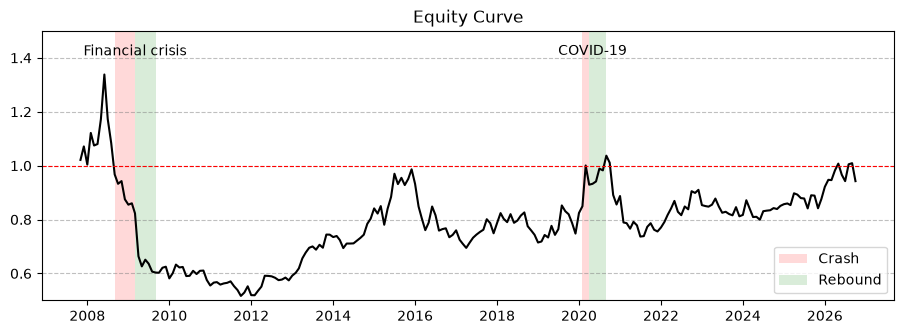

In [17]:
windows = {"Financial crisis": (("2008-09", "2009-02"), ("2009-03", "2009-08")),
           "COVID-19":         (("2020-02", "2020-03"), ("2020-04", "2020-08"))}

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.set_ylim(0.5, 1.5)
ax.plot(eq.index.to_timestamp(), eq, color="black")
ax.axhline(1, color="red", linestyle="--", lw=0.8)
ax.grid(axis="y", color="grey", linestyle="--", alpha=0.5)
for k, (c, r) in windows.items():
    annot_rng = eq[c[0]:r[1]].index
    annot_mid = annot_rng[len(annot_rng) // 2].to_timestamp()
    ax.annotate(k, xy=(annot_mid, 1.45), ha="center", va="top", fontsize=10, color="black")
    crash, rebound = eq[c[0]:c[1]].index, eq[r[0]:r[1]].index
    ax.axvspan(crash[0].to_timestamp(), crash[-1].to_timestamp(how="end"), color="red", alpha=0.15, lw=0)
    ax.axvspan(rebound[0].to_timestamp(), rebound[-1].to_timestamp(how="end"), color="green", alpha=0.15, lw=0)
ax.legend(handles=[
        Patch(facecolor="red", alpha=0.15, label="Crash"),
        Patch(facecolor="green", alpha=0.15, label="Rebound"),
    ], loc="lower right")

ax.set_title("Equity Curve")
plt.show()

In [18]:
dd = eq / eq.cummax() - 1

print(pd.Series({
    "Ann. return": eq.iloc[-1] ** (12 / len(net)) - 1,
    "Ann. vol": net.std() * 12 ** 0.5,
    "Sharpe": net.mean() / net.std() * 12 ** 0.5,
    "Worst month": net.min(),
    "Max drawdown": dd.min(),
    "Ann. turnover": turnover.mean() * 12,
    "Ann. cost": cost.mean() * 12,
}).round(4))

print(f"\ndrawdown trough {dd.idxmin()}, from peak {eq[:dd.idxmin()].idxmax()}")

print("\nFive worst months:")
print(net.nsmallest(5).round(4).to_string())


Ann. return     -0.0031
Ann. vol         0.1571
Sharpe           0.0589
Worst month     -0.1937
Max drawdown    -0.6140
Ann. turnover    8.8187
Ann. cost        0.0044
dtype: float64

drawdown trough 2011-10, from peak 2008-06

Five worst months:
Date
2009-04   -0.1937
2008-07   -0.1235
2020-11   -0.1184
2021-02   -0.1106
2008-09   -0.1074
Freq: M


In [19]:
long_leg = (held.clip(lower=0) * ret).sum(axis=1).loc[held.index]
short_leg = (-held.clip(upper=0) * ret).sum(axis=1).loc[held.index]
mkt = sp_m.pct_change().reindex(held.index)

def total(r, phase):
    return (1 + r[slice(*phase)]).prod() - 1

rets = {}
for k, phases in windows.items():
    rets[k] = pd.DataFrame({
        "Long": [total(long_leg, ph) for ph in phases],
        "Short": [total(short_leg, ph) for ph in phases],
        "Net": [total(net, ph) for ph in phases],
        "Market": [total(mkt, ph) for ph in phases],
    }, index=["Crash", "Rebound"])

print("--- Realized returns by phase ---")
for n, df in rets.items():
    print(f"\n{n}:")
    print(df.round(3))

--- Realized returns by phase ---

Financial crisis:
          Long  Short    Net  Market
Crash   -0.505 -0.372 -0.206  -0.418
Rebound  0.272  0.696 -0.295   0.404

COVID-19:
          Long  Short    Net  Market
Crash   -0.203 -0.388  0.214  -0.194
Rebound  0.382  0.387 -0.018   0.361


In [20]:

print("Monthly betas: ")
for n, r in [("Long", long_leg), ("Short", short_leg), ("Net", net)]:
    beta = np.cov(r, mkt, ddof=1)[0, 1] / np.var(mkt, ddof=1)
    print(f"  {n}: {beta:.3f}")

Monthly betas: 
  Long: 1.037
  Short: 1.198
  Net: -0.160


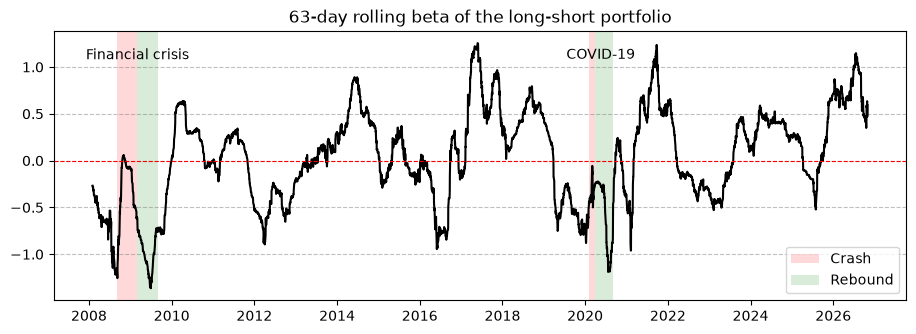

In [21]:
# exposure on daily returns: a monthly window cannot resolve the 2008 or 2020 shock
dret = p.pct_change()
dret = dret[dret.index.to_period("M").isin(held.index)]
wd = held.reindex(dret.index.to_period("M")).set_axis(dret.index)
dmkt = sp.pct_change().reindex(dret.index).dropna()
dnet = (wd * dret).sum(axis=1)
dlong = (wd.clip(lower=0) * dret).sum(axis=1)
dshort = (-wd.clip(upper=0) * dret).sum(axis=1)

beta = dnet.rolling(63).cov(dmkt) / dmkt.rolling(63).var()



fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(beta.index, beta, color="black")
ax.axhline(0, color="red", linestyle="--", lw=0.8)
ax.grid(axis="y", color="grey", linestyle="--", alpha=0.5)
for k, (c, r) in windows.items():
    annot_rng = dmkt[c[0]:r[1]]
    annot_mid = annot_rng.index[len(annot_rng) // 2]
    ax.annotate(k, xy=(annot_mid, 1.2), ha="center", va="top", fontsize=10, color="black")
    ax.axvspan(*dmkt[c[0]:c[1]].index[[0, -1]], color="red", alpha=0.15, lw=0)
    ax.axvspan(*dmkt[r[0]:r[1]].index[[0, -1]], color="green", alpha=0.15, lw=0)
ax.legend(handles=[
        Patch(facecolor="red", alpha=0.15, label="Crash"),
        Patch(facecolor="green", alpha=0.15, label="Rebound"),
    ], loc="lower right")

ax.set_title("63-day rolling beta of the long-short portfolio")
plt.show()


In [22]:
def beta_of(r, m):
    return np.cov(r.reindex(m.index), m)[0, 1] / np.var(m, ddof=1)

dfs = {}
for k, phases in windows.items():
    crash = dmkt[slice(*phases[0])]
    rebound = dmkt[slice(*phases[1])]
    dfs[k] = pd.DataFrame({
        "Long": [beta_of(dlong, crash), beta_of(dlong, rebound)],
        "Short": [beta_of(dshort, crash), beta_of(dshort, rebound)],
        "Net": [beta_of(dnet, crash), beta_of(dnet, rebound)],
    }, index=["Crash", "Rebound"])
    

print("--- Daily betas by phase ---")
for n, df in dfs.items():
    print(f"\n{n}:")
    print(df.round(2))

--- Daily betas by phase ---

Financial crisis:
         Long  Short   Net
Crash    0.97   1.16 -0.19
Rebound  0.72   1.75 -1.03

COVID-19:
         Long  Short   Net
Crash    0.95   1.20 -0.25
Rebound  0.92   1.52 -0.60


## Report

The rebound behavior explained in Section 3 is visible in this exercise. The loser leg consistently carries more beta than the winner leg and the gap widens when the market turns. Through the 2009 rebound the short book ran a beta of 1.75 against 0.72 for the long book. The portfolio is dollar netural, but in the given scenario we observe that it is significantly short-beta.

The realized returns follow the pattern with losers gaining 69.6% against the winners' 27.2%. 
The overall long-short lost 29.5% into a rising market. The worst month of the sample (April 2009) at -19.4% falls inside the rebound and displays the sharp loss in recovery notion. In the COVID-19 rebound, the legs were essentially identical (38.2% and 38.7%). The strategy lost only 1.8% in that period. The damaging factor is therefore beta spread between the legs rather than the rebound itself.